# 05 - Bootstrap confidence intervals and paired differences

Mirrors `notebooks_withseed/04_bootstrap_ci`: 95% bootstrap intervals on the pooled out-of-fold
predictions, plus paired differences between methods computed on identical resamples.

**One limitation specific to this cohort.** The handcrafted baseline exists only for the 148 OSF
subjects; Pooja's cohort has no equivalent scalar metrics. So handcrafted comparisons are restricted
to the OSF subset, while frozen and fine-tuned comparisons use whichever cohort is loaded.

In [1]:
import os, sys, json
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import warnings; warnings.filterwarnings('ignore')
import numpy as np, torch
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
OSF, OUT = '../data/preprocessed', '../results_parcel'
MODEL, SUFFIX = 'base', 'cortical'
cv = StratifiedKFold(5, shuffle=True, random_state=123)

# Use the COMBINED frozen features so every method here covers the same subjects.
# Mixing the 161-subject parcel cohort with 309-subject fine-tune results in one chart
# would compare numbers computed on different people.
Xc_path = f'{OUT}/combined_frozen_{MODEL}_{SUFFIX}.npy'
assert os.path.exists(Xc_path), 'run notebook 03 first (it writes the combined frozen features)'
X_comb = np.load(Xc_path)
osf_y  = np.load(f'{OSF}/labels.npy')
par_y  = np.load(f'{OUT}/parcel_labels_{SUFFIX}.npy')
labels = np.concatenate([osf_y, par_y])
N = len(labels)
assert len(X_comb) == N, f'feature/label mismatch: {len(X_comb)} vs {N}'
print(f'combined cohort: {X_comb.shape} | {N} subjects '
      f'(OSF {len(osf_y)} + parcel {len(par_y)})')

def oof_lr(X, y):
    pred, prob = np.zeros(len(y), int), np.zeros(len(y))
    for tr, te in cv.split(X, y):
        m = LogisticRegression(max_iter=2000).fit(X[tr], y[tr])
        pred[te], prob[te] = m.predict(X[te]), m.predict_proba(X[te])[:, 1]
    return pred, prob

M = []
p, pr = oof_lr(X_comb, labels); M.append(('Frozen combined + LR', p, pr, labels))

ft = f'{OUT}/finetune_combined_{MODEL}.pt'
if os.path.exists(ft):
    d = torch.load(ft, map_location='cpu', weights_only=False)
    y_all = d['labels']
    for nf, r in sorted(d.get('cv', {}).items(), reverse=True):
        M.append((f'Fine-tune combined last-{11-nf} + NN', r['nn_pred'], r['nn_prob'], y_all))
        M.append((f'Fine-tune combined last-{11-nf} + LR', r['lr_pred'], r['lr_prob'], y_all))
else:
    print('note: no fine-tune checkpoint yet, run notebook 04 first')
print(f'{len(M)} methods assembled')

combined cohort: (309, 8192) | 309 subjects (OSF 148 + parcel 161)
7 methods assembled


In [2]:
def boot(pred, y, metric, nb=2000, seed=123):
    rng = np.random.default_rng(seed); idx = np.arange(len(y)); v = []
    for _ in range(nb):
        b = rng.choice(idx, len(y), replace=True)
        try: v.append(metric(y[b], pred[b]))
        except ValueError: pass
    return metric(y, pred), *np.percentile(v, [2.5, 97.5])

rows = []
for name, pred, prob, y in M:
    a, alo, ahi = boot(pred, y, accuracy_score)
    u, ulo, uhi = boot(prob, y, roc_auc_score)
    rows.append((name, a, alo, ahi, u, ulo, uhi))
    print(f'{name:38s} acc {a:.3f} [{alo:.3f},{ahi:.3f}]  AUC {u:.3f} [{ulo:.3f},{uhi:.3f}]')

Frozen combined + LR                   acc 0.825 [0.783,0.867]  AUC 0.903 [0.864,0.936]
Fine-tune combined last-1 + NN         acc 0.841 [0.799,0.880]  AUC 0.893 [0.852,0.928]
Fine-tune combined last-1 + LR         acc 0.838 [0.799,0.877]  AUC 0.902 [0.860,0.936]
Fine-tune combined last-2 + NN         acc 0.828 [0.786,0.871]  AUC 0.883 [0.838,0.921]
Fine-tune combined last-2 + LR         acc 0.828 [0.786,0.871]  AUC 0.895 [0.851,0.930]
Fine-tune combined last-3 + NN         acc 0.835 [0.790,0.877]  AUC 0.876 [0.832,0.916]
Fine-tune combined last-3 + LR         acc 0.828 [0.786,0.871]  AUC 0.893 [0.851,0.930]


In [3]:
# Paired differences against the first method, on identical resamples.
def boot_diff(a, b, y, metric, nb=2000, seed=123):
    rng = np.random.default_rng(seed); idx = np.arange(len(y)); d = []
    for _ in range(nb):
        s = rng.choice(idx, len(y), replace=True)
        try: d.append(metric(y[s], a[s]) - metric(y[s], b[s]))
        except ValueError: pass
    return metric(y, a) - metric(y, b), *np.percentile(d, [2.5, 97.5])

if len(M) > 1:
    ref_name, ref_pred, ref_prob, ref_y = M[0]
    print(f'Paired differences vs {ref_name}\n')
    for name, pred, prob, y in M[1:]:
        if len(y) != len(ref_y):
            print(f'{name:38s} skipped (different cohort size)'); continue
        da, lo, hi = boot_diff(pred, ref_pred, y, accuracy_score)
        sig = 'YES' if (lo > 0 or hi < 0) else 'no'
        print(f'{name:38s} D acc {da:+.3f} [{lo:+.3f},{hi:+.3f}]  sig? {sig}')

Paired differences vs Frozen combined + LR

Fine-tune combined last-1 + NN         D acc +0.016 [-0.003,+0.039]  sig? no
Fine-tune combined last-1 + LR         D acc +0.013 [-0.003,+0.032]  sig? no
Fine-tune combined last-2 + NN         D acc +0.003 [-0.019,+0.026]  sig? no
Fine-tune combined last-2 + LR         D acc +0.003 [-0.019,+0.029]  sig? no
Fine-tune combined last-3 + NN         D acc +0.010 [-0.023,+0.042]  sig? no
Fine-tune combined last-3 + LR         D acc +0.003 [-0.019,+0.029]  sig? no


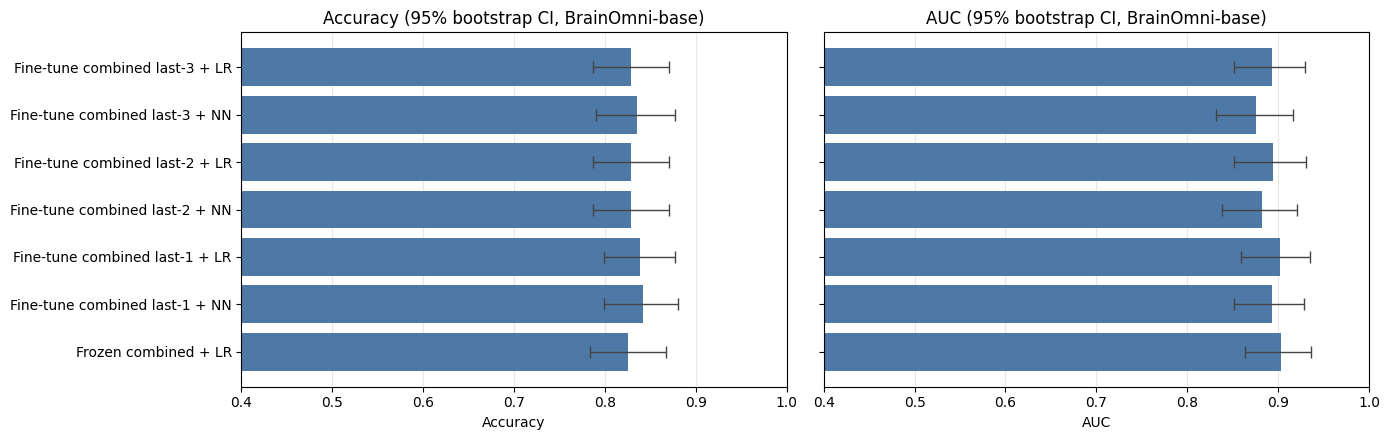

saved parcel_bootstrap_comparison_base.png


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 1 + 0.5*len(rows)))
y = np.arange(len(rows))
for ax, (vi, lo_i, hi_i), lab in ((ax1, (1,2,3), 'Accuracy'), (ax2, (4,5,6), 'AUC')):
    v  = [r[vi] for r in rows]
    el = [r[vi]-r[lo_i] for r in rows]; eh = [r[hi_i]-r[vi] for r in rows]
    ax.barh(y, v, xerr=[el, eh], capsize=4, color='#4E79A7', error_kw=dict(lw=1, ecolor='#444'))
    ax.set_yticks(y); ax.set_yticklabels([r[0] for r in rows] if ax is ax1 else [])
    ax.set_xlim(0.4, 1.0); ax.set_xlabel(lab); ax.grid(axis='x', alpha=0.3); ax.set_axisbelow(True)
    ax.set_title(f'{lab} (95% bootstrap CI, BrainOmni-{MODEL})')
plt.tight_layout()
fname = f'parcel_bootstrap_comparison_{MODEL}.png'
plt.savefig(f'{OUT}/{fname}', dpi=150, bbox_inches='tight'); plt.show()
print('saved', fname)

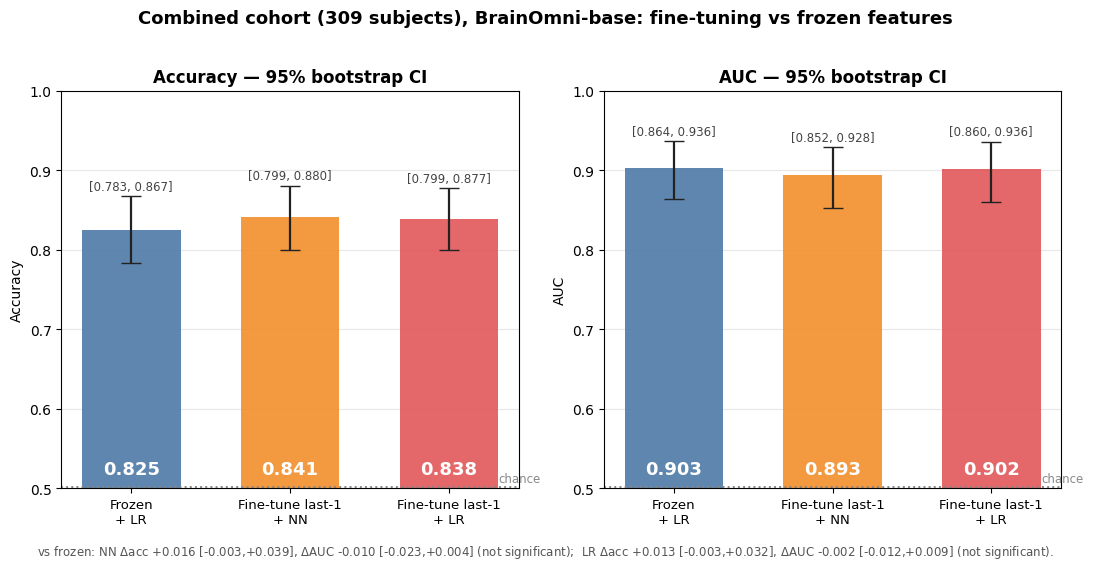

saved finetune_vs_frozen_combined_base.png
  Frozen
+ LR        acc 0.825 (np.float64(0.7831715210355987), np.float64(0.8673139158576052))  auc 0.903 (np.float64(0.8636395021312042), np.float64(0.9362875205759755))
  Fine-tune last-1   acc 0.841 (np.float64(0.7993527508090615), np.float64(0.8802588996763754))  auc 0.893 (np.float64(0.8517106583336485), np.float64(0.9284356930441265))
  Fine-tune last-1   acc 0.838 (np.float64(0.7992718446601942), np.float64(0.8770226537216829))  auc 0.902 (np.float64(0.8596958479127002), np.float64(0.9355828542884244))


In [5]:
# Vertical-bar version: fine-tuned vs frozen on the same 309 subjects.
# Error bars are 95% bootstrap CIs (asymmetric, hence the 2xN yerr array).
# The footnote carries the paired test, which is the statistic that actually
# decides the question -- overlapping CIs alone are not a significance test.
# NOTE: the paired-diff numbers used to be hardcoded text copied from a tiny run;
# they are now computed live so this cell is correct for whichever MODEL is loaded.
import numpy as np, torch
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

d = torch.load(f'{OUT}/finetune_combined_{MODEL}.pt', map_location='cpu', weights_only=False)
cvr = d['cv'][10]; y = np.asarray(d['labels']); N = len(y)

X = np.load(f'{OUT}/combined_frozen_{MODEL}_{SUFFIX}.npy')
fz_pred, fz_prob = np.zeros(N, int), np.zeros(N)
for tr, te in StratifiedKFold(5, shuffle=True, random_state=123).split(X, y):
    m = LogisticRegression(max_iter=2000).fit(X[tr], y[tr])
    fz_pred[te], fz_prob[te] = m.predict(X[te]), m.predict_proba(X[te])[:, 1]

M = [('Frozen\n+ LR',            fz_pred, fz_prob, '#4E79A7'),
     ('Fine-tune last-1\n+ NN',  np.asarray(cvr['nn_pred']), np.asarray(cvr['nn_prob']), '#F28E2B'),
     ('Fine-tune last-1\n+ LR',  np.asarray(cvr['lr_pred']), np.asarray(cvr['lr_prob']), '#E15759')]

def boot(p, pr, nb=2000, seed=123):
    rng = np.random.default_rng(seed); A, U = [], []
    for _ in range(nb):
        b = rng.choice(N, N, replace=True)
        if len(np.unique(y[b])) < 2: continue
        A.append(accuracy_score(y[b], p[b])); U.append(roc_auc_score(y[b], pr[b]))
    return np.percentile(A, [2.5, 97.5]), np.percentile(U, [2.5, 97.5])

def boot_diff(p, pr, nb=2000, seed=123):
    # paired against the frozen reference, same resamples as `boot` above
    rng = np.random.default_rng(seed); dA, dU = [], []
    for _ in range(nb):
        b = rng.choice(N, N, replace=True)
        if len(np.unique(y[b])) < 2: continue
        dA.append(accuracy_score(y[b], p[b]) - accuracy_score(y[b], fz_pred[b]))
        dU.append(roc_auc_score(y[b], pr[b]) - roc_auc_score(y[b], fz_prob[b]))
    da = accuracy_score(y, p) - accuracy_score(y, fz_pred)
    du = roc_auc_score(y, pr) - roc_auc_score(y, fz_prob)
    return da, np.percentile(dA, [2.5, 97.5]), du, np.percentile(dU, [2.5, 97.5])

R = []
for tag, p, pr, col in M:
    (al, ah), (ul, uh) = boot(p, pr)
    R.append(dict(tag=tag, col=col, acc=accuracy_score(y, p), aci=(al, ah),
                  auc=roc_auc_score(y, pr), uci=(ul, uh)))

fig, axes = plt.subplots(1, 2, figsize=(11, 5.6))
for ax, key, cik, name in [(axes[0], 'acc', 'aci', 'Accuracy'), (axes[1], 'auc', 'uci', 'AUC')]:
    xs = np.arange(len(R))
    vals = [r[key] for r in R]
    # asymmetric error bars: bootstrap CIs are not symmetric about the point estimate
    err = np.array([[r[key] - r[cik][0] for r in R], [r[cik][1] - r[key] for r in R]])
    ax.bar(xs, vals, 0.62, yerr=err, color=[r['col'] for r in R], alpha=.9,
           capsize=7, error_kw=dict(lw=1.6, ecolor='#222'))
    for i, r in enumerate(R):
        ax.text(i, 0.513, f'{r[key]:.3f}', ha='center', va='bottom',
                fontweight='bold', fontsize=13, color='white')
        ax.text(i, r[cik][1] + .008, f'[{r[cik][0]:.3f}, {r[cik][1]:.3f}]',
                ha='center', fontsize=8.5, color='#444')
    ax.axhline(0.502, color='#888', ls=':', lw=1.4)
    ax.text(len(R) - .42, 0.508, 'chance', color='#888', fontsize=8.5, ha='right')
    ax.set_xticks(xs); ax.set_xticklabels([r['tag'] for r in R], fontsize=9.5)
    ax.set_ylim(0.5, 1.0); ax.set_ylabel(name)
    ax.set_title(f'{name} — 95% bootstrap CI', fontsize=12, fontweight='bold')
    ax.grid(axis='y', alpha=.3); ax.set_axisbelow(True)

# paired diff vs frozen, computed live (not copy-pasted) so it's correct for this MODEL
da_nn, aci_nn, du_nn, uci_nn = boot_diff(np.asarray(cvr['nn_pred']), np.asarray(cvr['nn_prob']))
da_lr, aci_lr, du_lr, uci_lr = boot_diff(np.asarray(cvr['lr_pred']), np.asarray(cvr['lr_prob']))
sig = lambda lo, hi: 'significant' if (lo > 0 or hi < 0) else 'not significant'

fig.suptitle(f'Combined cohort (309 subjects), BrainOmni-{MODEL}: fine-tuning vs frozen features',
             fontsize=13, fontweight='bold', y=.99)
fig.text(.5, .015,
         'vs frozen: NN ' +
         rf'$\Delta$acc {da_nn:+.3f} [{aci_nn[0]:+.3f},{aci_nn[1]:+.3f}], ' +
         rf'$\Delta$AUC {du_nn:+.3f} [{uci_nn[0]:+.3f},{uci_nn[1]:+.3f}] ({sig(*aci_nn)});  ' +
         'LR ' +
         rf'$\Delta$acc {da_lr:+.3f} [{aci_lr[0]:+.3f},{aci_lr[1]:+.3f}], ' +
         rf'$\Delta$AUC {du_lr:+.3f} [{uci_lr[0]:+.3f},{uci_lr[1]:+.3f}] ({sig(*aci_lr)}).',
         ha='center', fontsize=8.5, color='#555')
plt.tight_layout(rect=[0, .04, 1, .97])
fname = f'finetune_vs_frozen_combined_{MODEL}.png'
plt.savefig(f'{OUT}/{fname}', dpi=150, bbox_inches='tight')
plt.show()
print('saved', fname)
for r in R: print(f"  {r['tag'][:16]:18s} acc {r['acc']:.3f} {r['aci']}  auc {r['auc']:.3f} {r['uci']}")

depths present: ['last-1', 'last-2', 'last-3']   missing: none

config             accuracy                 AUC                      delta-acc vs frozen   
-------------------------------------------------------------------------------------------
frozen + LR        0.825 [0.783,0.867]      0.903 [0.864,0.936]      (reference)           
last-1 + NN        0.841 [0.799,0.880]      0.893 [0.852,0.928]      +0.016 [-0.003,+0.039]
last-1 + LR        0.838 [0.799,0.877]      0.902 [0.860,0.936]      +0.013 [-0.003,+0.032]
last-2 + NN        0.828 [0.786,0.871]      0.883 [0.838,0.921]      +0.003 [-0.019,+0.026]
last-2 + LR        0.828 [0.786,0.871]      0.895 [0.851,0.930]      +0.003 [-0.019,+0.029]
last-3 + NN        0.835 [0.790,0.877]      0.876 [0.832,0.916]      +0.010 [-0.023,+0.042]
last-3 + LR        0.828 [0.786,0.871]      0.893 [0.851,0.930]      +0.003 [-0.019,+0.029]

* = 95% CI excludes zero


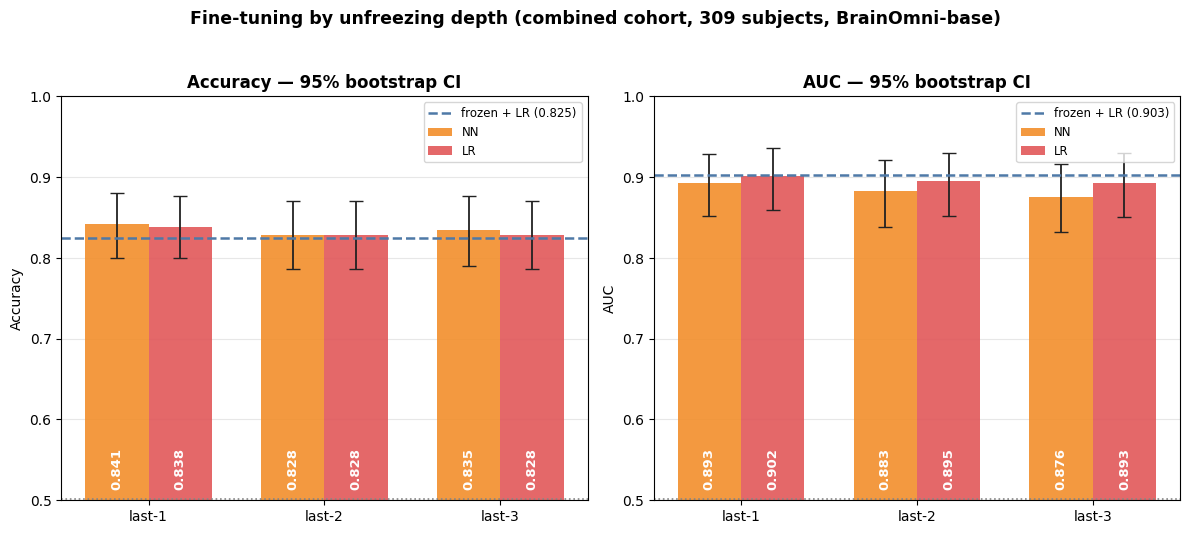


saved ../results_parcel/depth_sweep_combined_base.png


In [6]:
# Depth sweep: NN and LR heads at each unfreezing depth, vs the frozen reference.
# Renders whatever depths exist in the checkpoint, so it is safe to run before
# notebook 04 has finished last-2 and last-3 -- missing depths are labelled.
# delta columns are PAIRED bootstrap differences against frozen on the same subjects.
import numpy as np, torch
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

d = torch.load(f'{OUT}/finetune_combined_{MODEL}.pt', map_location='cpu', weights_only=False)
y = np.asarray(d['labels']); N = len(y)

# frozen reference on the same subjects
X = np.load(f'{OUT}/combined_frozen_{MODEL}_{SUFFIX}.npy')
fz_pred, fz_prob = np.zeros(N, int), np.zeros(N)
for tr, te in StratifiedKFold(5, shuffle=True, random_state=123).split(X, y):
    m = LogisticRegression(max_iter=2000).fit(X[tr], y[tr])
    fz_pred[te], fz_prob[te] = m.predict(X[te]), m.predict_proba(X[te])[:, 1]

def boot(p, pr, nb=2000, seed=123):
    rng = np.random.default_rng(seed); A, U = [], []
    for _ in range(nb):
        b = rng.choice(N, N, replace=True)
        if len(np.unique(y[b])) < 2: continue
        A.append(accuracy_score(y[b], p[b])); U.append(roc_auc_score(y[b], pr[b]))
    return np.percentile(A, [2.5, 97.5]), np.percentile(U, [2.5, 97.5])

def bdiff(pa, pra, nb=2000, seed=123):
    rng = np.random.default_rng(seed); A, U = [], []
    for _ in range(nb):
        b = rng.choice(N, N, replace=True)
        if len(np.unique(y[b])) < 2: continue
        A.append(accuracy_score(y[b], pa[b]) - accuracy_score(y[b], fz_pred[b]))
        U.append(roc_auc_score(y[b], pra[b]) - roc_auc_score(y[b], fz_prob[b]))
    return (accuracy_score(y, pa) - accuracy_score(y, fz_pred), np.percentile(A, [2.5, 97.5]),
            roc_auc_score(y, pra) - roc_auc_score(y, fz_prob), np.percentile(U, [2.5, 97.5]))

rows = []
(al, ah), (ul, uh) = boot(fz_pred, fz_prob)
rows.append(dict(depth='frozen', head='LR', acc=accuracy_score(y, fz_pred), aci=(al, ah),
                 auc=roc_auc_score(y, fz_prob), uci=(ul, uh), dacc=None))
have = sorted(d['cv'].keys(), reverse=True)          # 10, 9, 8 -> last-1, last-2, last-3
for nf in have:
    r = d['cv'][nf]
    for head, pk, qk in [('NN', 'nn_pred', 'nn_prob'), ('LR', 'lr_pred', 'lr_prob')]:
        p, pr = np.asarray(r[pk]), np.asarray(r[qk])
        (al, ah), (ul, uh) = boot(p, pr)
        da, aci, du, uci = bdiff(p, pr)
        rows.append(dict(depth=f'last-{11-nf}', head=head, acc=accuracy_score(y, p), aci=(al, ah),
                         auc=roc_auc_score(y, pr), uci=(ul, uh),
                         dacc=(da, aci), dauc=(du, uci)))

missing = [f'last-{11-n}' for n in (10, 9, 8) if n not in d['cv']]
print(f'depths present: {[f"last-{11-n}" for n in have]}   missing: {missing or "none"}')
print()
hdr = f'{"config":18s} {"accuracy":24s} {"AUC":24s} {"delta-acc vs frozen":22s}'
print(hdr); print('-' * len(hdr))
for r in rows:
    tag = f'{r["depth"]} + {r["head"]}'
    a = f'{r["acc"]:.3f} [{r["aci"][0]:.3f},{r["aci"][1]:.3f}]'
    u = f'{r["auc"]:.3f} [{r["uci"][0]:.3f},{r["uci"][1]:.3f}]'
    if r['dacc'] is None:
        dd = '(reference)'
    else:
        da, (l, h) = r['dacc']
        dd = f'{da:+.3f} [{l:+.3f},{h:+.3f}]' + ('  *' if l > 0 or h < 0 else '')
    print(f'{tag:18s} {a:24s} {u:24s} {dd:22s}')
print('\n* = 95% CI excludes zero')

# grouped bars, NN vs LR at each depth, frozen as a reference line
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
depths = [f'last-{11-n}' for n in have]
for ax, key, cik, name in [(axes[0], 'acc', 'aci', 'Accuracy'), (axes[1], 'auc', 'uci', 'AUC')]:
    xs = np.arange(len(depths)); w = 0.36
    for j, (head, col) in enumerate([('NN', '#F28E2B'), ('LR', '#E15759')]):
        sel = [next(r for r in rows if r['depth'] == dp and r['head'] == head) for dp in depths]
        vals = [r[key] for r in sel]
        err = np.array([[r[key] - r[cik][0] for r in sel], [r[cik][1] - r[key] for r in sel]])
        ax.bar(xs + (j - .5) * w, vals, w, yerr=err, label=head, color=col, alpha=.9,
               capsize=5, error_kw=dict(lw=1.3, ecolor='#222'))
        for x, v in zip(xs + (j - .5) * w, vals):
            ax.text(x, 0.513, f'{v:.3f}', ha='center', va='bottom', fontsize=9.5,
                    fontweight='bold', color='white', rotation=90)
    fz = rows[0][key]
    ax.axhline(fz, color='#4E79A7', ls='--', lw=1.8, label=f'frozen + LR ({fz:.3f})')
    ax.axhline(0.502, color='#888', ls=':', lw=1.2)
    ax.set_xticks(xs); ax.set_xticklabels(depths)
    ax.set_ylim(0.5, 1.0); ax.set_ylabel(name)
    ax.set_title(f'{name} — 95% bootstrap CI', fontsize=12, fontweight='bold')
    ax.legend(fontsize=8.5, loc='upper right'); ax.grid(axis='y', alpha=.3); ax.set_axisbelow(True)

sub = f'unfreezing depth (combined cohort, 309 subjects, BrainOmni-{MODEL})'
if missing: sub += f'  —  {", ".join(missing)} not yet run'
fig.suptitle(f'Fine-tuning by {sub}', fontsize=12.5, fontweight='bold', y=.98)
plt.tight_layout(rect=[0, 0, 1, .95])
fname = f'depth_sweep_combined_{MODEL}.png'
plt.savefig(f'{OUT}/{fname}', dpi=150, bbox_inches='tight')
plt.show()
print('\nsaved', f'{OUT}/{fname}')